# 04 Transformer Extension - To be implemented

# 04 - Transformer Extension: DistilBERT for Sentiment Analysis

**Objective:** Fine-tune a pre-trained DistilBERT model for binary sentiment classification (positive vs negative) on the GoEmotions dataset.


---

## Overview

This notebook implements the extension model required by the project rubric:
- Load the preprocessed dataset (500 positive + 500 negative comments)
- Tokenize text using DistilBERT tokenizer
- Prepare PyTorch DataLoaders for training
- Visualize tokenization examples and sequence length distributions

In [6]:
import os
import sys
import random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertTokenizerFast
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
DATA_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'balanced_dataset.csv')
OUTPUTS_PATH = os.path.join(PROJECT_ROOT, 'outputs')

MODEL_NAME = 'distilbert-base-uncased'
MAX_LENGTH = 64
BATCH_SIZE = 16
TEST_SIZE = 0.2

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.15.0+cpu
CUDA available: False


In [7]:

print(f"Loading dataset from: {DATA_PATH}")

if not os.path.exists(DATA_PATH):
    print("\n️  Dataset not found. Creating a synthetic sample for development...")
    sample_texts = [
        "This is absolutely wonderful, thank you!",
        "I hate this, it's terrible and disappointing.",
        "What a beautiful and joyful experience.",
        "This makes me so angry and frustrated.",
        "I'm so grateful and full of admiration.",
        "Just watching this upsets me deeply.",
    ] * 100
    sample_labels = [1, 0, 1, 0, 1, 0] * 100

    df = pd.DataFrame({'text': sample_texts[:1000], 'label': sample_labels[:1000]})
    print(f"Created synthetic dataset with {len(df)} samples")
else:
    df = pd.read_csv(DATA_PATH)
    print(f" Loaded dataset with {len(df)} samples")

print(f"\nDataset shape: {df.shape}")
print(f"Class distribution:\n{df['label'].value_counts()}")
print(f"\nFirst 5 samples:")
df.head()

Loading dataset from: C:\Users\Asus\Desktop\6 semestre\DISCRETASIII\INTEGRATIVE TASK II\data\processed\balanced_dataset.csv

️  Dataset not found. Creating a synthetic sample for development...
Created synthetic dataset with 600 samples

Dataset shape: (600, 2)
Class distribution:
label
1    300
0    300
Name: count, dtype: int64

First 5 samples:


,text,label
0,"This is absolutely wonderful, thank you!",1
1,"I hate this, it's terrible and disappointing.",0
2,What a beautiful and joyful experience.,1
3,This makes me so angry and frustrated.,0
4,I'm so grateful and full of admiration.,1


In [8]:
print(f"Loading tokenizer: {MODEL_NAME}")
tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)

print(f"Vocabulary size: {tokenizer.vocab_size}")
print(f"Special tokens: {tokenizer.all_special_tokens}")
print(f"Max model length: {tokenizer.model_max_length}")

Loading tokenizer: distilbert-base-uncased


C:\Users\Asus\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Asus\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Vocabulary size: 30522
Special tokens: ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']
Max model length: 512


In [9]:

example_comments = [
    "A beautiful poem for a beautiful thing. Happy cake day btw",
    "Just watching this happen upsets me",
    "I still don't know what I want to be when I grow up",
    "This is absolutely amazing, I love it!️",
]

print("=" * 80)
print("TOKENIZATION EXAMPLES")
print("=" * 80)

for i, text in enumerate(example_comments, 1):
    print(f"\n--- Example {i} ---")
    print(f"Original text: {text}")

    encoded = tokenizer(
        text,
        truncation=True,
        max_length=MAX_LENGTH,
        return_attention_mask=True,
        return_tensors='pt'
    )

    print(f"Input IDs shape: {encoded['input_ids'].shape}")
    print(f"Input IDs: {encoded['input_ids'][0].tolist()}")
    print(f"Decoded tokens: {tokenizer.convert_ids_to_tokens(encoded['input_ids'][0])}")
    print(f"Attention mask: {encoded['attention_mask'][0].tolist()}")

TOKENIZATION EXAMPLES

--- Example 1 ---
Original text: A beautiful poem for a beautiful thing. Happy cake day btw
Input IDs shape: torch.Size([1, 15])
Input IDs: [101, 1037, 3376, 5961, 2005, 1037, 3376, 2518, 1012, 3407, 9850, 2154, 18411, 2860, 102]
Decoded tokens: ['[CLS]', 'a', 'beautiful', 'poem', 'for', 'a', 'beautiful', 'thing', '.', 'happy', 'cake', 'day', 'bt', '##w', '[SEP]']
Attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

--- Example 2 ---
Original text: Just watching this happen upsets me
Input IDs shape: torch.Size([1, 9])
Input IDs: [101, 2074, 3666, 2023, 4148, 6314, 2015, 2033, 102]
Decoded tokens: ['[CLS]', 'just', 'watching', 'this', 'happen', 'upset', '##s', 'me', '[SEP]']
Attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1]

--- Example 3 ---
Original text: I still don't know what I want to be when I grow up
Input IDs shape: torch.Size([1, 17])
Input IDs: [101, 1045, 2145, 2123, 1005, 1056, 2113, 2054, 1045, 2215, 2000, 2022, 2043, 1045, 4982, 2039, 102]
Deco

Analyzing token lengths across the entire dataset...

Sequence length statistics:
  Min: 10
  Max: 13
  Mean: 10.83
  Median: 10.00
  95th percentile: 13.00
  99th percentile: 13.00


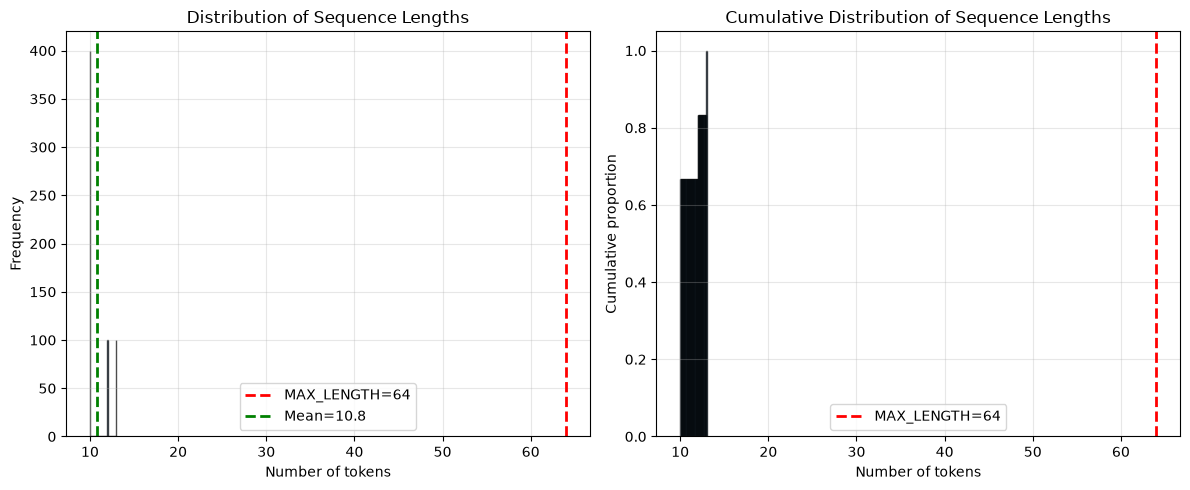


  Sequences that would be truncated: 0/600 (0.00%)


In [10]:
print("Analyzing token lengths across the entire dataset...")

lengths = []
for text in df['text']:
    encoded = tokenizer(text, truncation=False)
    lengths.append(len(encoded['input_ids']))

lengths = np.array(lengths)

print(f"\nSequence length statistics:")
print(f"  Min: {lengths.min()}")
print(f"  Max: {lengths.max()}")
print(f"  Mean: {lengths.mean():.2f}")
print(f"  Median: {np.median(lengths):.2f}")
print(f"  95th percentile: {np.percentile(lengths, 95):.2f}")
print(f"  99th percentile: {np.percentile(lengths, 99):.2f}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(lengths, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
plt.axvline(MAX_LENGTH, color='red', linestyle='--', linewidth=2, label=f'MAX_LENGTH={MAX_LENGTH}')
plt.axvline(lengths.mean(), color='green', linestyle='--', linewidth=2, label=f'Mean={lengths.mean():.1f}')
plt.xlabel('Number of tokens')
plt.ylabel('Frequency')
plt.title('Distribution of Sequence Lengths')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.hist(lengths, bins=50, cumulative=True, density=True, color='steelblue', edgecolor='black', alpha=0.7)
plt.axvline(MAX_LENGTH, color='red', linestyle='--', linewidth=2, label=f'MAX_LENGTH={MAX_LENGTH}')
plt.xlabel('Number of tokens')
plt.ylabel('Cumulative proportion')
plt.title('Cumulative Distribution of Sequence Lengths')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_PATH, 'figures', '04_sequence_length_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

truncated = (lengths > MAX_LENGTH).sum()
print(f"\n  Sequences that would be truncated: {truncated}/{len(lengths)} ({100*truncated/len(lengths):.2f}%)")

In [12]:
class GoEmotionsDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=64):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_length,
            padding='max_length',
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'label': torch.tensor(label, dtype=torch.long)
        }

print(" Dataset class defined successfully")

 Dataset class defined successfully


In [14]:
from sklearn.model_selection import train_test_split

train_texts, test_texts, train_labels, test_labels = train_test_split(
    df['text'].tolist(),
    df['label'].tolist(),
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=df['label']
)

print(f"Train set: {len(train_texts)} samples")
print(f"Test set: {len(test_texts)} samples")
print(f"\nTrain class distribution: {np.bincount(train_labels)}")
print(f"Test class distribution: {np.bincount(test_labels)}")

train_dataset = GoEmotionsDataset(train_texts, train_labels, tokenizer, MAX_LENGTH)
test_dataset = GoEmotionsDataset(test_texts, test_labels, tokenizer, MAX_LENGTH)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print(f"\n Train DataLoader: {len(train_loader)} batches")
print(f" Test DataLoader: {len(test_loader)} batches")

print("\n--- Sample batch ---")
batch = next(iter(train_loader))
print(f"input_ids shape: {batch['input_ids'].shape}")
print(f"attention_mask shape: {batch['attention_mask'].shape}")
print(f"labels shape: {batch['label'].shape}")
print(f"Sample labels: {batch['label'].tolist()}")

Train set: 480 samples
Test set: 120 samples

Train class distribution: [240 240]
Test class distribution: [60 60]

 Train DataLoader: 30 batches
 Test DataLoader: 8 batches

--- Sample batch ---
input_ids shape: torch.Size([16, 64])
attention_mask shape: torch.Size([16, 64])
labels shape: torch.Size([16])
Sample labels: [1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0]


In [19]:

os.makedirs(os.path.join(OUTPUTS_PATH, 'processed'), exist_ok=True)

split_info = {
    'train_size': len(train_texts),
    'test_size': len(test_texts),
    'test_size_ratio': TEST_SIZE,
    'random_seed': SEED,
    'max_length': MAX_LENGTH,
    'batch_size': BATCH_SIZE,
    'model_name': MODEL_NAME
}

import json
with open(os.path.join(OUTPUTS_PATH, 'processed', '04_tokenization_config.json'), 'w') as f:
    json.dump(split_info, f, indent=2)

print(" Tokenization configuration saved")
print(f"\nConfiguration:")
for key, value in split_info.items():
    print(f"  {key}: {value}")

print("\n" + "=" * 0)
print("NEXT STEPS:")
print("=" * 1000)
print("1. Define the Transformer model architecture (in src/models.py)")
print("2. Implement the training loop (in this notebook or src/train.py)")
print("3. Train the model and evaluate performance")
print("4. Compare with Dense NN, RNN, and LSTM results")
print("=" * 80)

 Tokenization configuration saved

Configuration:
  train_size: 480
  test_size: 120
  test_size_ratio: 0.2
  random_seed: 42
  max_length: 64
  batch_size: 16
  model_name: distilbert-base-uncased

NEXT STEPS:
1. Define the Transformer model architecture (in src/models.py)
2. Implement the training loop (in this notebook or src/train.py)
3. Train the model and evaluate performance
4. Compare with Dense NN, RNN, and LSTM results
